# Independent end-to-end runtime

本 notebook 集中展示主 GRAM 与 baseline 的时间柱状图，以及历史 / 新增 GRAM 配置的耗时表。
不使用检测图中的择优配置替代固定主设置。计时重建函数完整定义在下方 `runtime-helper` 单元格中：
完整 run.log 墙钟时间，加上缓存命中时省略的基础训练实测时间；本地训练已包含在墙钟内，不重复计入。
缓存读取开销保留，这是独立运行成本的重建值，不是关闭缓存后的重新测量。

每个配置有多少完整 seeds 就平均多少。先在 noise type 内平均 seeds，再对噪声等权平均。
主方法与 baseline 的柱状图使用现有完整三 seed 记录；新增网格耗时表标出实际 n。
输出至 `analysis/figures/runtime/`，不运行训练。

磁盘导出仅保存 PDF 图，不生成 JSON 或其他格式的辅助文件；中间数据保留在 notebook 内存中。


In [1]:
%matplotlib inline
from pathlib import Path
from itertools import product
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
DATASETS = ['cifar10', 'cifar100', 'atis', 'qnli', 'adult', 'letter']
NOISE_TYPES = ['symmetric', 'pairflip', 'instance']
RHOS = [0.2, 0.4]
BASELINE_METHODS = ['aum_b', 'el2n_b', 'early_loss_b', 'forgetting_b', 'knn_label_disagreement_b', 'moderate_b', 'cleanlab_b', 'misdetect_b', 'dalc', 'robust_alc', 'active_label_cleaning', 'active_label_correction', 'graph_label_propagation', 'cleannet']
DATASET_LABELS = {'cifar10': 'CIFAR-10', 'cifar100': 'CIFAR-100', 'atis': 'ATIS', 'qnli': 'QNLI', 'adult': 'Adult', 'letter': 'Letter'}
METHOD_LABELS = {'ours': 'GRAM (Ours)', 'aum_b': 'AUM', 'el2n_b': 'EL2N', 'early_loss_b': 'Early-Loss', 'forgetting_b': 'Forgetting', 'knn_label_disagreement_b': 'kNN-dis.', 'moderate_b': 'Moderate', 'cleanlab_b': 'CleanLab', 'misdetect_b': 'MisDetect', 'dalc': 'DALC', 'robust_alc': 'Robust ALC', 'active_label_cleaning': 'Active Cleaning', 'active_label_correction': 'Active Correction', 'graph_label_propagation': 'Graph LP', 'cleannet': 'CleanNet'}

def find_project_root(start):
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate/'results/detection').is_dir():return candidate
    raise FileNotFoundError('Cannot find results/detection')
PROJECT_ROOT=find_project_root(Path.cwd())
RESULTS_ROOT=PROJECT_ROOT/'results/detection'
OUTPUT_DIR=PROJECT_ROOT/'analysis/figures/runtime'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
EXPECTED_BUDGETS={rho:np.array([.001,.005,.01,.025]+[round(.05*i,12) for i in range(1,round(rho/.05)+1)]) for rho in RHOS}
if str(PROJECT_ROOT) not in sys.path:sys.path.insert(0,str(PROJECT_ROOT))
plt.rcParams.update({'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none'})


In [2]:
"""Reconstruct independent detection costs from recorded runs and training costs."""

import json
import math
from pathlib import Path
import re


_COMPLETION = re.compile(
    r"run_completed protocol=full_pool_detection elapsed_seconds=([\d.]+)"
)
_TRAINING = re.compile(
    r"shared_training_artifact_ready cache_hit=(True|False) "
    r"fingerprint=([0-9a-f]{64}) .*?source_train_seconds=([\d.]+)"
)


def independent_detection_runtime(directory, results_root, summary=None):
    """Add omitted base training to full logged wall time, once per run.

    This is a reconstruction, retaining recorded cache I/O overhead. Training
    uses the original logged fingerprint even when pairing metadata was edited.
    Local training and selector retraining are already in the logged wall time.
    """
    directory, results_root = Path(directory), Path(results_root)
    if summary is None:
        summary = json.loads((directory / "summary.json").read_text())
    phase_seconds = float(summary["elapsed_seconds"])
    log_path = directory / "run.log"
    log = log_path.read_text()
    completions = list(_COMPLETION.finditer(log))
    if not completions:
        raise ValueError(f"Missing completed end-to-end timing: {log_path}")
    completion = completions[-1]
    wall_seconds = float(completion.group(1))
    if not (math.isfinite(phase_seconds) and phase_seconds > 0
            and math.isfinite(wall_seconds) and wall_seconds > 0
            and wall_seconds + 0.002 >= phase_seconds):
        raise ValueError(f"Invalid or inconsistent elapsed time: {log_path}")

    training_entries = list(_TRAINING.finditer(log[:completion.start()]))
    cache_hit = summary["shared_training_artifact_cache_hit"]
    base_seconds, added_seconds = 0.0, 0.0
    fingerprint, training_source = "", ""
    overridden = False
    if cache_hit is None:
        if training_entries:
            raise ValueError(f"Unexpected shared training for an uncached selector: {log_path}")
    else:
        if not isinstance(cache_hit, bool) or not training_entries:
            raise ValueError(f"Missing shared-training provenance: {log_path}")
        training = training_entries[-1]
        if (training.group(1) == "True") != cache_hit:
            raise ValueError(f"Cache status disagrees with original log: {log_path}")
        fingerprint = training.group(2)
        overridden = fingerprint != summary["shared_training_artifact_fingerprint"]
        if overridden and summary.get("fingerprint_override", {}).get(
            "original_shared_training_artifact_fingerprint"
        ) != fingerprint:
            raise ValueError(f"Unexplained training fingerprint change: {log_path}")
        manifest_path = (
            results_root / "_shared_training_artifacts" / summary["dataset"]
            / summary["noise_type"] / f"rho{summary['rho']:g}"
            / f"seed{summary['seed']}" / fingerprint[:16] / "manifest.json"
        )
        manifest = json.loads(manifest_path.read_text())
        if manifest.get("fingerprint") != fingerprint or any(
            manifest.get(key) != summary[key]
            for key in ("dataset", "noise_type", "rho", "seed")
        ):
            raise ValueError(f"Training manifest does not match the original run: {manifest_path}")
        base_seconds = float(manifest["train_seconds"])
        if (not math.isfinite(base_seconds) or base_seconds <= 0
                or not math.isclose(base_seconds, float(training.group(3)), abs_tol=0.001)):
            raise ValueError(f"Invalid or inconsistent base training time: {manifest_path}")
        added_seconds = base_seconds if cache_hit else 0.0
        training_source = manifest_path.relative_to(results_root).as_posix()

    return {
        "elapsed_seconds": phase_seconds,
        "observed_end_to_end_seconds": wall_seconds,
        "base_training_seconds": base_seconds,
        "added_training_seconds": added_seconds,
        "end_to_end_seconds": wall_seconds + added_seconds,
        "cache_status": {True: "hit", False: "miss", None: "not applicable"}[cache_hit],
        "original_training_fingerprint": fingerprint,
        "uses_original_fingerprint": overridden,
        "training_time_source": training_source,
        "wall_time_source": log_path.relative_to(results_root).as_posix(),
    }


## 时间开销：GRAM 主设置与 baseline

图仅导出为矢量 `analysis/figures/runtime/detection_runtime.pdf`。
Notebook 预览同样使用 300 DPI，柱子及图例色块的边框线宽为 0.9 pt。
按参考图 `analysis/figures/detection/isolation/detection_tradeoff_noise20_40_budget20_40.pdf` 排为 2×6 面板（19.5 × 6.3 英寸）：
上排为 20% noise w/ 20% budget，下排为 40% noise w/ 40% budget；每排左上角使用 14 pt 加粗设置标注。
顶部统一方法图例采用 8 列，列间距为 1.5 倍图例字号，横轴不显示 `Methods` 标签或方法名刻度；最下方另起一行标注 `(a)`–`(f)` 和数据集名，并在名称下方使用 14 pt 斜体标注 `(n=样本数)`（数据集名称保持 18 pt 常规字体）。样本数取自各运行 `summary.json: sample_count`，表示实验使用的完整训练池大小。采用常规字重的 DejaVu Sans 无衬线字体，
坐标轴、刻度、面板标签和图例分别使用 18、15、18 和 12.75 pt（统一放大 50%）。
纵轴为秒，采用从 0 开始的线性刻度；同一数据集上下两排共用纵轴范围，不同数据集分别设置上限，并显示浅灰色水平网格。
GRAM 固定使用 `config.methods.DEFAULT_GRAM_VARIANT`（当前为 `main_adaptive_mixture`），
不使用检测 notebook 的 beta trade-off 图的择优结果，也不混入任何 ablation。

**方法排序与颜色：**从左到右为分数校准、核验状态推断、标签修正，最后为 GRAM。
同类方法分别使用柔和浅蓝、浅绿、淡紫色系的不同深浅，GRAM 使用柔和杏色。
采用稍密的三重重复细纹理；纹理只用于辅助区分方法，不编码 noise rate；方法图例按柱子的顺序逐行排列，GRAM 显示名称为 `GRAM (Ours)`。
DALC、Robust ALC 仅展示完整版本，组间留少量间距。
分类对应 `src/baselines/policy.py` 的 score-calibration、status-inference 和 correction 分支。

**独立 end-to-end 计时口径：**每次运行都计入完整基础训练，即使实际执行时复用了训练缓存。
使用 `run.log` 最后一次 `run_completed` 中的完整运行墙钟时间，
覆盖数据加载、噪声注入、初始训练或缓存读取、完整查询轨迹、离线检测评估及结果文件写入。
缓存命中时，补回原始训练 fingerprint 对应的共享训练 `manifest.json: train_seconds`；
缓存未命中时基础训练已在完整墙钟时间内，不重复计入。
方法自身的后续训练、warm-start 和 selector 训练已经包含在墙钟时间中，也不重复叠加。

`end_to_end_seconds = observed_end_to_end_seconds + added_training_seconds`，
其中 `added_training_seconds = base_training_seconds`（缓存命中）或 `0`（缓存未命中/不使用共享训练）。
这是基于已有记录重建的独立运行成本；缓存命中运行仍保留记录中的缓存读取开销，
并非重新关闭缓存后测量的耗时。训练时间按每种方法、每次运行完整计入，不在方法之间摊销。
`summary.json: elapsed_seconds` 仅覆盖检测阶段，保留为原始诊断值，不再用于柱高。

**统计口径：**每个 dataset / noise rate / method 展示一根柱，
在固定 noise rate 下，对 3 seeds × 3 noise types 共 9 次完整运行的独立 end-to-end 耗时取算术平均。
20% / 40% noise rate 分排展示，不跨 noise rate 平均；各次运行最大查询预算等于该次 noise rate。
单位为秒/次运行，不除以样本数，也不跨数据集或 checkpoint 平均。
下方内嵌的 `independent_detection_runtime` 函数完成计时重建；
`runtime_runs` 保留原始运行和来源路径，`runtime_by_rate` 保留按 noise rate 拆分的审计值，
`runtime_summary` 保存实际绘图使用的分 noise rate 均值。
GRAM ablation 和新增网格时间表列于下方。

In [3]:
import sys
from matplotlib.patches import Patch
from matplotlib.colors import to_hex
from matplotlib.ticker import MaxNLocator, StrMethodFormatter

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from config.methods import DEFAULT_GRAM_VARIANT, method_config
from src.utils.run_logging import completed_run_exists

RUNTIME_MAIN = DEFAULT_GRAM_VARIANT
# Groups follow the baseline policy's mechanisms. The proposed method is last.
RUNTIME_GROUPS = {
    "Score calibration": [
        "aum_b", "el2n_b", "early_loss_b", "forgetting_b", "cleanlab_b",
        "knn_label_disagreement_b", "moderate_b",
    ],
    "Status inference": ["misdetect_b", "cleannet", "graph_label_propagation"],
    "Label correction": [
        "dalc", "robust_alc",
        "active_label_cleaning", "active_label_correction",
    ],
    "GRAM": ["ours"],
}
RUNTIME_METHODS = [method for methods in RUNTIME_GROUPS.values() for method in methods]
assert len(RUNTIME_METHODS) == len(set(RUNTIME_METHODS)) == len(BASELINE_METHODS) + 1
assert set(RUNTIME_METHODS) == {"ours", *BASELINE_METHODS}
assert RUNTIME_METHODS[-1] == "ours"
# Soft, desaturated palettes: no dark endpoint; texture identifies methods.
RUNTIME_GROUP_PALETTES = {
    "Score calibration": [
        "#C7DDE9", "#BDD5E3", "#B2CCDD", "#A8C3D6", "#9DBAD0", "#93B1C9", "#89A8C2",
    ],
    "Status inference": ["#CBDCCB", "#B7CFBF", "#A4C1B3"],
    "Label correction": ["#D4CAE3", "#BFB4D6", "#B5A9D0", "#AA9EC9"],
    "GRAM": ["#E7B29A"],
}
RUNTIME_GROUP_HATCHES = {'Score calibration': ['///', '\\\\\\', 'xxx', '...', '---', '+++', 'ooo'], 'Status inference': ['///', 'xxx', '...'], 'Label correction': ['\\\\\\', '...', '---', '+++'], 'GRAM': ['///']}
RUNTIME_METHOD_COLORS, RUNTIME_METHOD_HATCHES = {}, {}
for family, methods in RUNTIME_GROUPS.items():
    assert len(methods) == len(RUNTIME_GROUP_PALETTES[family]) == len(RUNTIME_GROUP_HATCHES[family])
    RUNTIME_METHOD_COLORS.update(zip(methods, RUNTIME_GROUP_PALETTES[family]))
    RUNTIME_METHOD_HATCHES.update(zip(methods, RUNTIME_GROUP_HATCHES[family]))
RUNTIME_SEEDS = [0, 1, 2]
runtime_rows = []
# Read just the main setting and baselines: unfinished ablation/grid runs must
# not change which runs enter the end-to-end comparison.
for dataset, noise, rho, method, seed in product(
    DATASETS, NOISE_TYPES, RHOS, RUNTIME_METHODS, RUNTIME_SEEDS
):
    directory = RESULTS_ROOT / dataset / noise / f"rho{rho:g}" / method
    if method == "ours":
        directory /= RUNTIME_MAIN
    directory /= f"seed{seed}"
    summary_path = directory / "summary.json"
    if not completed_run_exists(
        directory, protocol="full_pool_detection",
        required_files=("summary.json", "metrics.csv", "config.json"),
    ):
        raise ValueError(f"Incomplete timing run: {directory}")
    summary = json.loads(summary_path.read_text())
    identity = dict(dataset=dataset, noise_type=noise, rho=rho, method=method, seed=seed)
    if any(summary.get(name) != value for name, value in identity.items()):
        raise ValueError(f"Timing summary identity mismatch: {summary_path}")
    if summary.get("protocol") != "full_pool_detection":
        raise ValueError(f"Unexpected timing protocol: {summary_path}")
    if method == "ours":
        config = json.loads((directory / "config.json").read_text())
        expected_config = json.loads(json.dumps(method_config("ours", RUNTIME_MAIN)))
        if (summary.get("gram_variant") != RUNTIME_MAIN
            or config.get("method_config") != expected_config):
            raise ValueError(f"Timing run is not the current main GRAM setting: {directory}")
    budgets = np.asarray(summary["budgets"], dtype=float)
    if (len(budgets) != len(EXPECTED_BUDGETS[rho])
        or not np.allclose(budgets, EXPECTED_BUDGETS[rho])):
        raise ValueError(f"Timing run has a different budget schedule: {summary_path}")
    runtime_rows.append({
        **identity,
        "sample_count": summary["sample_count"],
        "gram_variant": RUNTIME_MAIN if method == "ours" else "",
        **independent_detection_runtime(directory, RESULTS_ROOT, summary),
        "local_training_seconds": summary["local_training_seconds"],
        "source": summary_path.relative_to(PROJECT_ROOT).as_posix(),
    })

runtime_runs = pd.DataFrame(runtime_rows)
# Dataset labels use the recorded full training-pool size across all plotted runs.
if not runtime_runs.groupby("dataset")["sample_count"].nunique().eq(1).all():
    raise ValueError("Inconsistent sample counts within a runtime dataset.")
runtime_sample_counts = runtime_runs.groupby("dataset")["sample_count"].first().astype(int).to_dict()
assert all(count > 0 for count in runtime_sample_counts.values())
runtime_keys = ["dataset", "noise_type", "rho", "method", "seed"]
expected_runtime_runs = pd.MultiIndex.from_tuples(
    list(product(DATASETS, NOISE_TYPES, RHOS, RUNTIME_METHODS, RUNTIME_SEEDS)),
    names=runtime_keys,
)
observed_runtime_runs = pd.MultiIndex.from_frame(runtime_runs[runtime_keys])
if (observed_runtime_runs.has_duplicates
    or len(expected_runtime_runs.difference(observed_runtime_runs))
    or len(observed_runtime_runs.difference(expected_runtime_runs))):
    raise ValueError("Timing comparison requires the complete, balanced seed/noise grid.")

# Keep each noise rate separate: its complete run ends at the matching budget.
runtime_by_rate = (
    runtime_runs.groupby(["dataset", "rho", "method"], as_index=False)
    .agg(mean_seconds=("end_to_end_seconds", "mean"),
         mean_observed_seconds=("observed_end_to_end_seconds", "mean"),
         mean_added_training_seconds=("added_training_seconds", "mean"),
         run_count=("end_to_end_seconds", "size"),
         seed_count=("seed", "nunique"), noise_count=("noise_type", "nunique"))
)
runtime_summary = runtime_by_rate.copy()
assert len(runtime_summary) == len(DATASETS) * len(RHOS) * len(RUNTIME_METHODS)
assert runtime_summary["run_count"].eq(len(RUNTIME_SEEDS) * len(NOISE_TYPES)).all()
assert runtime_summary["seed_count"].eq(len(RUNTIME_SEEDS)).all()
assert runtime_summary["noise_count"].eq(len(NOISE_TYPES)).all()
assert set(runtime_runs.loc[runtime_runs["method"].eq("ours"), "gram_variant"]) == {RUNTIME_MAIN}
assert np.allclose(runtime_summary["mean_seconds"],
                   runtime_summary["mean_observed_seconds"] + runtime_summary["mean_added_training_seconds"])
runtime_cache_summary = (
    runtime_runs.groupby(["method", "cache_status"]).size().unstack(fill_value=0)
    .reindex(RUNTIME_METHODS)
)
print(f"Independent end-to-end runtime: {len(runtime_runs):,} runs; {len(runtime_summary)} bars; "
      f"{len(RUNTIME_SEEDS) * len(NOISE_TYPES)} runs/bar; "
      f"noise rates shown separately with matching budgets; GRAM={RUNTIME_MAIN}.")
print(f"Base training restored for {runtime_runs['added_training_seconds'].gt(0).sum():,} cached runs.")

Independent end-to-end runtime: 1,620 runs; 180 bars; 9 runs/bar; noise rates shown separately with matching budgets; GRAM=main_adaptive_mixture.
Base training restored for 1,336 cached runs.


analysis/figures/runtime/detection_runtime.pdf


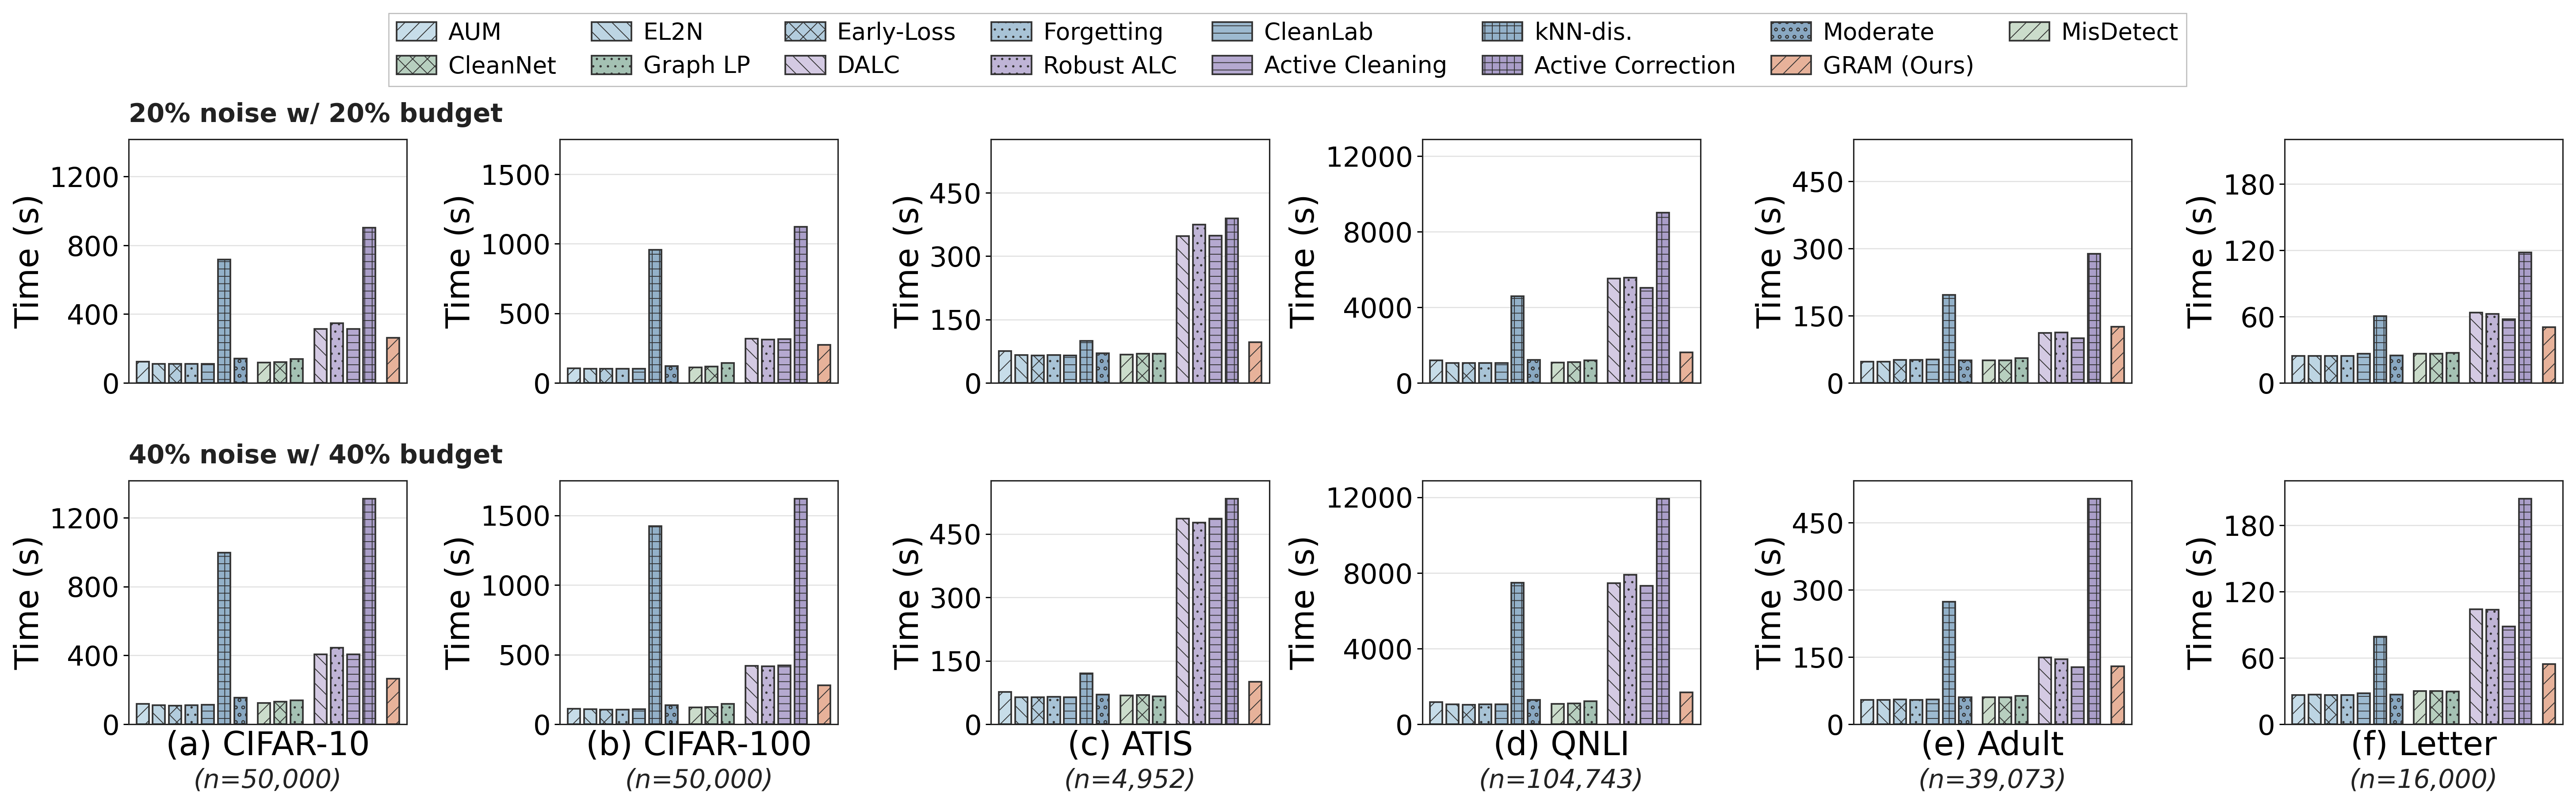

In [4]:
def plot_runtime():
    # Reference layout: shared legend, two setting rows, dataset names below.
    style = {
        "font.family": "DejaVu Sans", "font.size": 15, "font.weight": "normal",
        "axes.labelsize": 18, "axes.labelweight": "normal", "axes.linewidth": 0.75,
        "xtick.labelsize": 15, "ytick.labelsize": 15,
        "hatch.linewidth": 0.45, "legend.fontsize": 12.75,
        "figure.dpi": 300, "savefig.dpi": 300, "savefig.bbox": None,
    }
    with plt.rc_context(style):
        row_rates = tuple(RHOS)
        fig, axes = plt.subplots(len(row_rates), len(DATASETS), figsize=(19.5, 6.3),
                                 sharex=True, sharey=False, squeeze=False)
        positions = np.arange(len(RUNTIME_METHODS), dtype=float)
        group_boundaries = np.cumsum([len(methods) for methods in RUNTIME_GROUPS.values()])[:-1]
        for boundary in group_boundaries:
            positions[boundary:] += 0.45

        for row_index, rho in enumerate(row_rates):
            for index, (ax, dataset) in enumerate(zip(axes[row_index], DATASETS)):
                panel = (runtime_summary[runtime_summary["dataset"].eq(dataset)
                                      & np.isclose(runtime_summary["rho"], rho)]
                         .set_index("method").reindex(RUNTIME_METHODS))
                values = panel["mean_seconds"].to_numpy()
                if not np.isfinite(values).all():
                    raise ValueError(f"Missing runtime plotting values: {dataset}, rho={rho}")
                bars = ax.bar(
                    positions, values, width=0.76, bottom=0,
                    color=[RUNTIME_METHOD_COLORS[m] for m in RUNTIME_METHODS],
                    edgecolor="#333333", linewidth=0.9,
                )
                for method, bar in zip(RUNTIME_METHODS, bars):
                    bar.set_hatch(RUNTIME_METHOD_HATCHES[method])
                ax.set_yscale("linear")
                dataset_max = runtime_summary.loc[
                    runtime_summary["dataset"].eq(dataset), "mean_seconds"
                ].max()
                ax.set_ylim(0, dataset_max * 1.08)
                ax.yaxis.set_major_locator(MaxNLocator(nbins=4, min_n_ticks=3))
                ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}"))
                ax.set_xlim(positions[0] - 0.85, positions[-1] + 0.85)
                ax.set_xticks([])
                ax.set_ylabel("Time (s)", fontsize=18, fontweight="normal", labelpad=2)
                xlabel = ""
                if row_index == len(row_rates) - 1:
                    xlabel = f"({chr(ord('a') + index)}) {DATASET_LABELS[dataset]}"
                ax.set_xlabel(xlabel, fontsize=18, fontweight="normal", labelpad=3)
                ax.tick_params(axis="y", which="major", labelsize=15, length=3, width=0.7, pad=2)
                ax.set_axisbelow(True)
                ax.xaxis.grid(False)
                ax.yaxis.grid(True, which="major", color="#D9D9D9", linewidth=0.6, linestyle="-", alpha=0.8)
                for spine in ax.spines.values():
                    spine.set_visible(True)
                    spine.set_color("#222222")
                    spine.set_linewidth(0.75)

        # Legend rows follow the same left-to-right method order as the bars.
        legend_columns = 8
        legend_rows = int(np.ceil(len(RUNTIME_METHODS) / legend_columns))
        legend_methods = [
            RUNTIME_METHODS[column + row * legend_columns]
            for column in range(legend_columns) for row in range(legend_rows)
            if column + row * legend_columns < len(RUNTIME_METHODS)
        ]
        legend = fig.legend(
            handles=[Patch(facecolor=RUNTIME_METHOD_COLORS[m], edgecolor="#333333",
                           linewidth=0.9, hatch=RUNTIME_METHOD_HATCHES[m], label=METHOD_LABELS[m])
                     for m in legend_methods],
            loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=legend_columns,
            frameon=True, fancybox=False, framealpha=1, facecolor="white", edgecolor="#BBBBBB",
            fontsize=12.75, handlelength=1.7, handleheight=0.85,
            handletextpad=0.5, columnspacing=1.5, labelspacing=0.45, borderpad=0.35,
        )
        legend.get_frame().set_linewidth(0.6)
        # Match the reference's left-aligned, bold setting headings above each row.
        fig.canvas.draw()
        legend_box = legend.get_window_extent(fig.canvas.get_renderer()).transformed(
            fig.transFigure.inverted()
        )
        panel_top = legend_box.y0 - 0.40 / fig.get_figheight()
        fig.subplots_adjust(left=0.052, right=0.993, top=panel_top, bottom=0.13,
                            wspace=0.55, hspace=0.40)
        for row_index, rho in enumerate(row_rates):
            row_box = axes[row_index, 0].get_position()
            fig.text(
                row_box.x0, row_box.y1 + 0.09 / fig.get_figheight(),
                f"{rho:.0%} noise w/ {rho:.0%} budget", ha="left", va="bottom",
                fontsize=14, fontweight="bold", color="#222222",
            )
        # Sample counts use a smaller italic line below the unchanged dataset labels.
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        for ax, dataset in zip(axes[-1], DATASETS):
            label_box = ax.xaxis.label.get_window_extent(renderer).transformed(
                fig.transFigure.inverted()
            )
            panel_box = ax.get_position()
            fig.text(
                (panel_box.x0 + panel_box.x1) / 2,
                label_box.y0 - 3 / 72 / fig.get_figheight(),
                f"(n={runtime_sample_counts[dataset]:,})",
                ha="center", va="top", fontsize=14, fontstyle="italic",
                fontweight="normal", color="#222222",
            )
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        runtime_path = OUTPUT_DIR / "detection_runtime.pdf"
        fig.savefig(runtime_path, format="pdf", dpi=300, bbox_inches=None, pad_inches=0, facecolor="white")
        print(runtime_path.relative_to(PROJECT_ROOT).as_posix())
        plt.show()
        plt.close(fig)
        return fig


runtime_figure = plot_runtime()

## GRAM 配置耗时：历史参考与新增网格

读取所有完整且配置匹配的 GRAM 结果。按配置 / 数据集 / noise type / rho 平均其可用 seeds，
再在固定 rho 内对三种噪声等权平均。表格仅在三种噪声都有记录时展示均值，n 不要求固定为 3。
历史参考表保留原有 18 个配置；全部配置的耗时、seed 数与来源保留在本 notebook 的 DataFrame 中。

In [5]:
from config.methods import GRAM_VARIANTS, GRAM_ABLATION_VARIANTS
timing_rows, timing_errors = [], []
expected_configs = {v: json.loads(json.dumps(method_config('ours', v))) for v in GRAM_VARIANTS}
for path in sorted(RESULTS_ROOT.glob('*/*/rho*/ours/*/seed*/summary.json')):
    directory=path.parent
    if not completed_run_exists(directory,protocol='full_pool_detection',required_files=('summary.json','config.json','metrics.csv')):
        continue
    summary=json.loads(path.read_text());variant=summary.get('gram_variant')
    if variant not in expected_configs:continue
    config=json.loads(path.with_name('config.json').read_text())
    if config.get('method_config')!=expected_configs[variant]:
        timing_errors.append({'source':str(path.relative_to(PROJECT_ROOT)),'reason':'configuration mismatch'});continue
    timing_rows.append({
        'dataset':summary['dataset'],'noise_type':summary['noise_type'],'rho':summary['rho'],'seed':summary['seed'],
        'variant':variant,'graph_neighbors':config['method_config']['graph_neighbors'],
        'beta':config['method_config'].get('iv_beta'),
        **independent_detection_runtime(directory,RESULTS_ROOT,summary),
        'source':path.relative_to(PROJECT_ROOT).as_posix(),
    })
gram_runtime_runs=pd.DataFrame(timing_rows)
assert not gram_runtime_runs.duplicated(['dataset','noise_type','rho','seed','variant']).any()
gram_runtime_by_noise=(gram_runtime_runs.groupby(['dataset','noise_type','rho','variant'],as_index=False)
    .agg(mean_seconds=('end_to_end_seconds','mean'),seed_count=('seed','nunique'),run_count=('seed','size')))
gram_runtime_summary=(gram_runtime_by_noise.groupby(['dataset','rho','variant'],as_index=False)
    .agg(mean_seconds=('mean_seconds','mean'),noise_count=('noise_type','nunique'),
         seed_count_min=('seed_count','min'),seed_count_max=('seed_count','max'),run_count=('run_count','sum')))
gram_runtime_summary['mean_seconds']=gram_runtime_summary.mean_seconds.where(gram_runtime_summary.noise_count.eq(len(NOISE_TYPES)))
runtime_variants=[DEFAULT_GRAM_VARIANT,*GRAM_ABLATION_VARIANTS]
legacy=gram_runtime_summary[gram_runtime_summary.variant.isin(runtime_variants)]
runtime_seconds_table=(legacy.pivot(index='variant',columns=['dataset','rho'],values='mean_seconds')
    .reindex(index=runtime_variants,columns=pd.MultiIndex.from_product([DATASETS,RHOS],names=['dataset','rho'])))
runtime_seconds_table.index.name='Variant'
display(runtime_seconds_table.style.format('{:,.2f}',na_rep='—')
    .set_caption('GRAM independent runtime (s): available-seed mean within noise, then equal noise mean')
    .set_properties(**{'font-size':'12px','white-space':'nowrap','padding':'5px 8px'})
    .set_properties(subset=pd.IndexSlice[[DEFAULT_GRAM_VARIANT],:],**{'font-weight':'bold','background-color':'#FFF1EB'}))
print(f'{len(gram_runtime_runs):,} GRAM runs; {len(gram_runtime_summary)} configuration/dataset/rate cells; n is retained below and in CSV.')
display(gram_runtime_summary.head(24))


3,960 GRAM runs; 936 configuration/dataset/rate cells; n is retained below and in CSV.


,dataset,rho,variant,mean_seconds,noise_count,seed_count_min,seed_count_max,run_count
0,adult,0.2,abl_beta0p1,147.807426,3,3,3,9
1,adult,0.2,abl_beta10,148.713315,3,3,3,9
2,adult,0.2,abl_beta100,147.796981,3,3,3,9
3,adult,0.2,abl_beta1000,139.761071,3,1,1,3
4,adult,0.2,abl_beta10000,135.960738,3,1,1,3
5,adult,0.2,abl_fixed_uniform_weights,145.148093,3,3,3,9
6,adult,0.2,abl_iv_only,129.630426,3,3,3,9
7,adult,0.2,abl_k10,111.602870,3,3,3,9
8,adult,0.2,abl_k100,175.646093,3,3,3,9
9,adult,0.2,abl_k25,118.082204,3,3,3,9
